# Copy number on a whole transcriptome section with Atera

10x Atera measures the whole transcriptome in situ, here 18,028 genes with a median of about 2,000 counts per cell. At
that depth, {func}`infercnvpy.tl.copy_number` can call copy number in single cells from the raw counts, while the
small imaging panels of the {doc}`Xenium tutorial <spatial_xenium>` need spatial smoothing. The section is from a breast
tumor with ductal carcinoma in situ (DCIS, grade 3), and {cite:t}`Wu2026` sequenced the DNA of laser-dissected regions
of the same section with low-pass whole genome sequencing (WGS). We can therefore compare the inferred profiles with
copy number measured on DNA, for groups of regions.

The tutorial

- runs `tl.copy_number` without reference cells and with two references, and compares the calls per cell type and the
  profiles with the WGS,
- shows what happens when a normal cell type is left out of the reference,
- compares single fits with the default of 5 restarts,
- looks briefly at {func}`infercnvpy.tl.detectability`.

It needs only infercnvpy. With 16 threads, each run of `tl.copy_number` took one to two minutes (printed below).

In [1]:
import importlib.metadata
import os
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.metrics import adjusted_rand_score

import infercnvpy as cnv

sc.set_figure_params(dpi=50, frameon=False, figsize=(4.5, 4.5))

## Load the data

{func}`infercnvpy.datasets.wu2026_atera_breast` downloads the data (88 MB) once and then reads it from the cache. The
data are a window of a preview dataset that 10x Genomics released under CC BY 4.0, and 10x made the preview with
development versions of the panel, protocols and software. Cite the dataset as printed below, and {cite:t}`Wu2026` for
the WGS. `adata.X` holds the raw counts, which `tl.copy_number` needs, and `adata.var` the genomic positions of the
genes.

In [2]:
adata = cnv.datasets.wu2026_atera_breast()
print(adata.uns["source"]["dataset"]["attribution"])
counts_per_cell = np.asarray(adata.X.sum(axis=1)).ravel()
print(f"median counts per cell: {np.median(counts_per_cell):.0f}")
adata

Preview Data: Atera In Situ Gene Expression, FFPE Human Breast Cancer. Atera Onboard Analysis (development version), 10x Genomics (2026, June 2). Licensed under CC BY 4.0. https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-breast-cancer


median counts per cell: 1959


AnnData object with n_obs × n_vars = 43700 × 18028
    obs: 'cell_type', 'pred_state', 'wgs_region', 'wgs_clone_group', 'wgs_region_ensemble_frac'
    var: 'gene_ids', 'chromosome', 'start', 'end'
    uns: 'source', 'wgs_truth', 'window_um'
    obsm: 'spatial'
    layers: None (.X)

`obs["cell_type"]` holds cell types from expression clustering, and `obs["pred_state"]` holds epithelial states,
transferred from the cells that {cite:t}`Wu2026` annotated. We call the epithelial cells in the normal luminal, normal
basal and ductal luminal states normal epithelium and give them their own type in `cell_type_ref`, the column that the
references below use. The other epithelial cells are mostly DCIS.

`obs["wgs_clone_group"]` marks the cells inside the dissected regions, grouped into the clone groups A, C and N of the
preprint. The outlines of the regions were placed on the section by hand from a figure of the preprint, with an error
of about 0.5 to 1 mm, so we compare whole clone groups only. Group N was meant as a normal control, but its WGS has
gains of 1q and 17q (table below) and its epithelium shows the tumor profile, so group N contains tumor (see
`adata.uns["wgs_truth"]["description"]`). The regions hold the stroma around the ducts as well, and the table counts
the cell types in each group.

In [3]:
cell_type = adata.obs["cell_type"].astype(str)
normal_states = ["Normal Luminal", "Normal Basal", "Ductal Luminal"]
normal_epithelium = (cell_type == "epithelial") & adata.obs["pred_state"].isin(normal_states)
adata.obs["cell_type_ref"] = pd.Categorical(cell_type.where(~normal_epithelium, "normal epithelium"))
# for the comparisons below: the other epithelial cells by the clone group of the WGS region around them
clone_group = adata.obs["wgs_clone_group"].astype(str)
other_epithelium = (cell_type == "epithelial") & ~normal_epithelium
adata.obs["group"] = adata.obs["cell_type_ref"].astype(str)
adata.obs.loc[other_epithelium, "group"] = np.where(
    clone_group[other_epithelium].isin(["A", "C", "N"]),
    "epithelium in " + clone_group[other_epithelium],
    "other epithelium",
)
pd.crosstab(adata.obs["cell_type_ref"], adata.obs["wgs_clone_group"].astype(str), margins=True)

wgs_clone_group,A,C,N,All
cell_type_ref,,,,
B/plasma,286,347,467,1100
T/NK,141,164,276,581
endothelial,337,600,751,1688
epithelial,425,942,177,1544
fibroblast,677,1053,1029,2759
myeloid,123,158,220,501
normal epithelium,37,50,167,254
smooth muscle/pericyte,507,718,872,2097
unassigned,283,494,436,1213


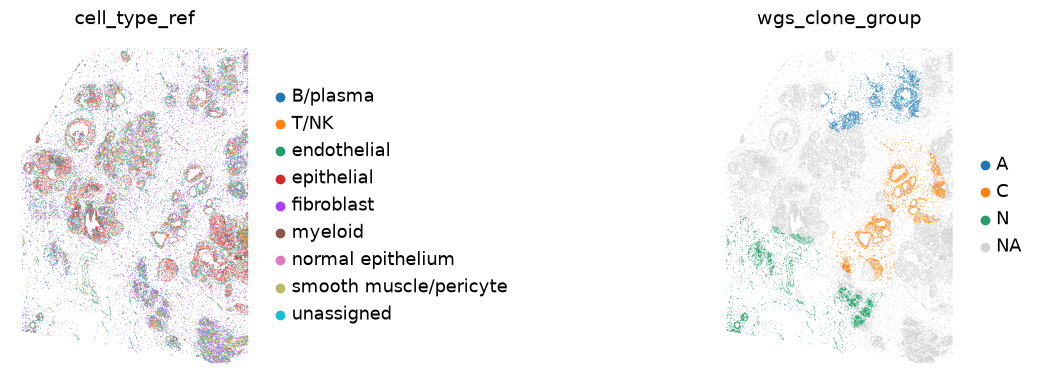

In [4]:
cnv.pl.spatial_cnv(adata, color=["cell_type_ref", "wgs_clone_group"], size=1, wspace=0.6)

The WGS table holds the log2 copy ratio of each chromosome arm per clone group, relative to the average of the genome.
A and C share losses of 2q, 3p, 8p and 9p and a gain of 17q. They differ on other arms, e.g. 13q and 18q are lower in A, 5q
and 11q are lower in C, and 4q is higher in C. The table in `uns` also lists two focal amplicons of the preprint, 11q13 with CCND1
and 12q14 to 15, as rows of kind "focal". We leave them out, because we compare whole arms.

In [5]:
wgs = adata.uns["wgs_truth"]["arms"].query("kind == 'arm'")
wgs = wgs.pivot(index="arm", columns="clone_group", values="log2")
arms = sorted(wgs.index, key=lambda arm: (int(arm[:-1]), arm[-1]))
wgs = wgs.loc[arms]
wgs.round(2)

clone_group,A,C,N
arm,,,
1p,-0.10,-0.05,0.06
1q,0.15,0.29,0.23
2p,0.06,0.11,0.02
2q,-0.36,-0.28,-0.03
3p,-0.49,-0.59,-0.05
3q,0.05,0.12,-0.07
4p,0.08,0.11,-0.09
4q,-0.03,0.24,-0.08
5p,0.19,0.12,-0.08


## Copy number without and with a reference

{func}`infercnvpy.tl.copy_number` fits a count model to the raw counts, with a diploid baseline, expression types and
clones (see {doc}`the API overview <../api>`). We run it three times:

1. without reference cells, so that it finds the diploid baseline in the data,
2. with immune cells, endothelial cells and fibroblasts as the reference, a common choice,
3. with all normal types, i.e. with smooth muscle cells and pericytes and the normal epithelium added.

The unassigned cells are in no reference, because we don't know what they are. Each run keeps its results under its own
`key_added`. With `calculate_gene_values=True`, a run also stores a log ratio per gene and cell. We average it per arm
over the epithelial cells of each clone group (a pseudobulk) and correlate it with the WGS over the 39 arms. The gene
values are a dense matrix of cells by genes, so `arm_profiles` removes them once it has used them.

In [6]:
# GRCh38 centromere midpoints (Mb), to assign each gene to an arm
centromere_mb = {
    "chr1": 123.4, "chr2": 93.9, "chr3": 90.9, "chr4": 50.0, "chr5": 48.8, "chr6": 59.8, "chr7": 60.1, "chr8": 45.2,
    "chr9": 43.0, "chr10": 39.8, "chr11": 53.4, "chr12": 35.5, "chr13": 17.7, "chr14": 17.2, "chr15": 19.0,
    "chr16": 36.8, "chr17": 25.1, "chr18": 18.5, "chr19": 26.2, "chr20": 28.1, "chr21": 12.0, "chr22": 15.0,
}  # fmt: skip
chromosome = adata.var["chromosome"].astype(str)
side = np.where(adata.var["start"] / 1e6 < chromosome.map(centromere_mb), "p", "q")
gene_arm = pd.Series(chromosome.str.removeprefix("chr") + side, index=adata.var_names).where(
    chromosome.isin(centromere_mb)
)
epithelial = (cell_type == "epithelial").to_numpy()


def arm_profiles(key):
    """Mean gene value per arm of the epithelial cells of each clone group; removes the gene values layer."""
    gene_values = adata.layers.pop(f"gene_values_{key}")
    used = adata.uns[key]["genes"].index
    columns = adata.var_names.get_indexer(used)
    profiles = {}
    for group in ["A", "C", "N"]:
        cells = epithelial & (clone_group == group).to_numpy()
        gene_mean = pd.Series(np.nanmean(gene_values[np.ix_(cells, columns)], axis=0), index=used)
        profiles[group] = gene_mean.groupby(gene_arm[used]).mean()
    return pd.DataFrame(profiles).loc[arms]


def wgs_correlation(profile):
    """Pearson r over the arms between the pseudobulk profiles and the WGS, per clone group and for A minus C."""
    r = {f"r {group}": np.corrcoef(profile[group], wgs[group])[0, 1] for group in ["A", "C"]}
    r["r A-C"] = np.corrcoef(profile["A"] - profile["C"], wgs["A"] - wgs["C"])[0, 1]
    return r


immune_stromal = ["T/NK", "B/plasma", "myeloid", "endothelial", "fibroblast"]
all_normal = [*immune_stromal, "smooth muscle/pericyte", "normal epithelium"]
runs = {
    "no reference": {},
    "immune, endothelial, fibroblast": {"reference_key": "cell_type_ref", "reference_cat": immune_stromal},
    "all normal types": {"reference_key": "cell_type_ref", "reference_cat": all_normal},
}
keys = dict(zip(runs, ["cn_none", "cn_immune_stromal", "cn_all_normal"], strict=True))
profiles, correlations = {}, {}
for name, kwargs in runs.items():
    start = time.perf_counter()
    cnv.tl.copy_number(adata, calculate_gene_values=True, key_added=keys[name], show_progress=False, **kwargs)
    print(f"{name}: {time.perf_counter() - start:.0f} s")
    profiles[name] = arm_profiles(keys[name])
    correlations[name] = wgs_correlation(profiles[name])

no reference: 69 s


immune, endothelial, fibroblast: 124 s


all normal types: 48 s


In [7]:
order = [
    "T/NK", "B/plasma", "myeloid", "endothelial", "fibroblast", "smooth muscle/pericyte", "unassigned",
    "normal epithelium", "epithelium in A", "epithelium in C", "epithelium in N", "other epithelium",
]  # fmt: skip
aneuploid = pd.DataFrame(
    {name: (adata.obs[key] == "aneuploid").groupby(adata.obs["group"]).mean() for name, key in keys.items()}
).loc[order]
aneuploid.insert(0, "cells", adata.obs["group"].value_counts())
aneuploid.round(3)

,cells,no reference,"immune, endothelial, fibroblast",all normal types
group,,,,
T/NK,2121,0.235,0.005,0.003
B/plasma,3631,0.412,0.013,0.008
myeloid,1761,0.222,0.010,0.005
endothelial,5480,0.168,0.004,0.003
fibroblast,8594,0.049,0.002,0.001
smooth muscle/pericyte,7024,0.374,0.285,0.003
unassigned,4887,0.555,0.519,0.500
normal epithelium,762,0.042,0.010,0.000
epithelium in A,425,0.918,0.868,0.840


The table gives the share of cells that each run calls aneuploid, per group. Without a reference, `tl.copy_number`
calls most of the epithelium of A and C aneuploid (92% and 95%), and also 17% to 41% of the immune and endothelial
cells and 37% of the smooth muscle cells and pericytes. Fibroblasts (4.9%) and the normal epithelium (4.2%) are
mostly diploid. With the immune, endothelial and fibroblast reference, the reference types drop to 1.3% or less, while
the smooth muscle cells and pericytes stay at 29% (see the next section). With all normal types in the reference, every
normal type is at 0.8% or less, and the epithelium of A and C stays mostly aneuploid (84% and 90%).

Two groups have no clear answer. Every run calls 50% to 56% of the unassigned cells aneuploid, and we don't know how
many of them are tumor cells. Every run also calls 74% to 76% of the epithelium in group N aneuploid, which fits the
tumor in the N regions, so these calls are not evidence of false calls.

In [8]:
pd.DataFrame(correlations).T.round(2)

,r A,r C,r A-C
no reference,0.81,0.81,0.85
"immune, endothelial, fibroblast",0.74,0.82,0.88
all normal types,0.73,0.81,0.89


Against the WGS, the three runs reach a Pearson r of 0.73 to 0.81 for A and 0.81 to 0.82 for C. The difference A minus
C tests whether the profiles separate the two clone groups, and its r is 0.85 without a reference and 0.88 and 0.89 with
the two references. With 39 arms, differences of a few hundredths in r are small compared with the uncertainty of r, so
the three runs match the WGS about equally well. The reference changes the calls of the normal cells much more than
the tumor profiles.

The plot shows the pseudobulk of the run with all normal types against the WGS, and labels the arms that differ from 0
by more than 0.3 in the WGS. The pseudobulk values are natural log ratios, each clone's profile is centered on its most
common level, and the pseudobulk includes the diploid cells of each group. The pseudobulk is therefore on another scale
than the WGS, with the gains near 0 and the losses below, so we compare the correlation only.

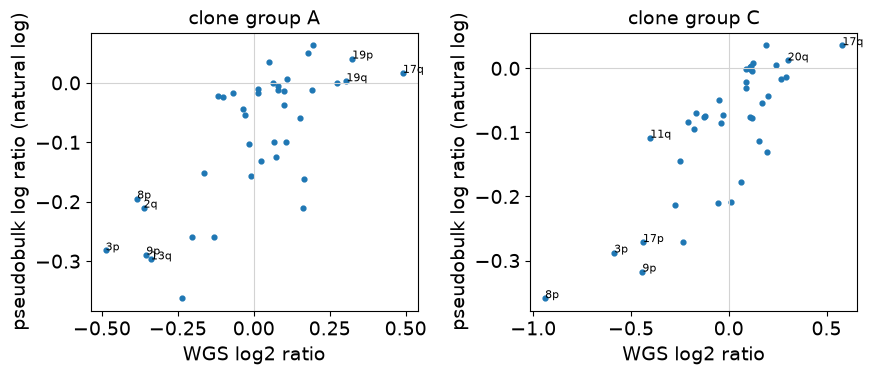

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, group in zip(axes, ["A", "C"], strict=True):
    profile = profiles["all normal types"][group]
    ax.axhline(0, color="lightgray", lw=0.8)
    ax.axvline(0, color="lightgray", lw=0.8)
    ax.scatter(wgs[group], profile, s=12)
    for arm in arms:
        if abs(wgs.loc[arm, group]) > 0.3:
            ax.annotate(arm, (wgs.loc[arm, group], profile[arm]), fontsize=8)
    ax.set(xlabel="WGS log2 ratio", ylabel="pseudobulk log ratio (natural log)", title=f"clone group {group}")
    ax.grid(False)
plt.tight_layout()

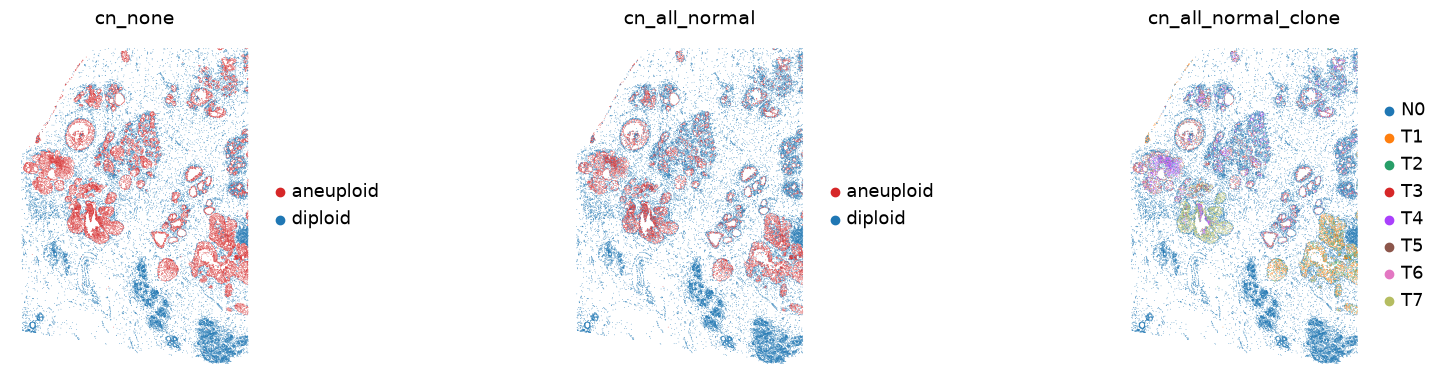

In [10]:
# aneuploid red, diploid and the diploid clone N0 blue
for key in ["cn_none", "cn_all_normal", "cn_all_normal_clone"]:
    adata.obs[key] = adata.obs[key].cat.remove_unused_categories()
    colors = dict(zip(adata.obs[key].cat.categories, sc.pl.palettes.default_20, strict=False))
    colors.update({"aneuploid": "#d62728", "diploid": "#1f77b4", "N0": "#1f77b4"})
    adata.uns[f"{key}_colors"] = [colors[c] for c in adata.obs[key].cat.categories]
cnv.pl.spatial_cnv(adata, color=["cn_none", "cn_all_normal", "cn_all_normal_clone"], size=1, wspace=0.4)

On the tissue, both runs call the ducts aneuploid and most of the stroma diploid, and the run without a reference
calls more scattered cells in the stroma aneuploid. The clones form patches within and between the ducts. The table
counts the epithelial cells of each clone group per clone of the run with all normal types.

In [11]:
pd.crosstab(adata.obs["group"], adata.obs["cn_all_normal_clone"]).loc[
    ["epithelium in A", "epithelium in C", "epithelium in N", "other epithelium", "unassigned"]
]

cn_all_normal_clone,N0,T1,T2,T3,T4,T5,T6,T7
group,,,,,,,,
epithelium in A,68,0,0,177,98,28,51,3
epithelium in C,93,228,110,343,31,45,90,2
epithelium in N,45,0,0,3,1,0,2,126
other epithelium,510,1649,952,1118,1032,907,499,1229
unassigned,2443,334,157,545,427,159,303,519


The clone groups fall into different clones only in part. The epithelium of A is mostly in T3 (177 cells), T4 (98) and
T6 (51), that of C in T3 (343), T1 (228) and T2 (110), and that of N in T7 (126). T1 and T2 hold C but no A, T4 holds
more A than C, and A and C share T3. Most of the epithelial cells in the clones lie outside the dissected regions
("other epithelium"), and the unassigned cells are spread over all clones.

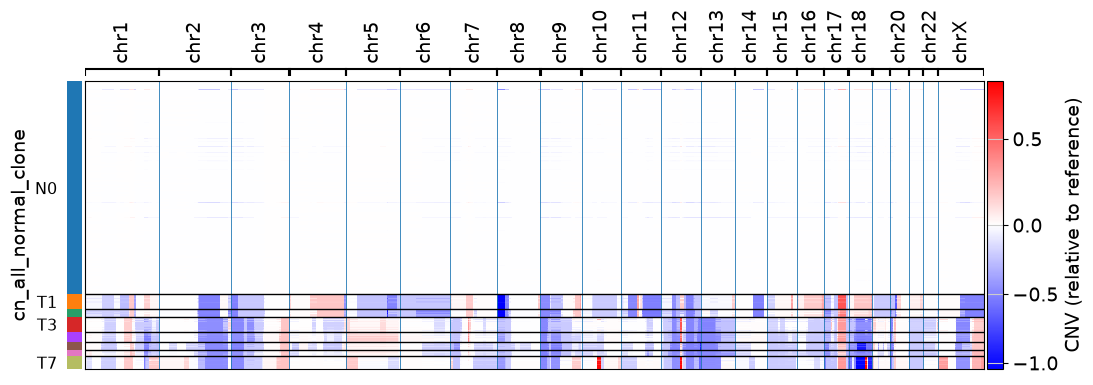

,n_cells,aneuploid,amplitude,burden
N0,32439,False,0.014,0.000
T1,2240,True,0.223,0.579
T2,1223,True,0.201,0.577
T3,2186,True,0.173,0.440
T4,1591,True,0.198,0.457
T5,1140,True,0.178,0.587
T6,947,True,0.164,0.541
T7,1934,True,0.175,0.487


In [12]:
cnv.pl.chromosome_heatmap(adata, groupby="cn_all_normal_clone", use_rep="cn_all_normal", figsize=(12, 4))
adata.uns["cn_all_normal"]["clones"].round(3)

The heatmap shows the profiles of the clones as natural log copy ratios. Most aneuploid clones have losses on 2q, 3p and
9p, which A and C share in the WGS, and T1 has a deep loss of 8p, which fits the 8p loss of C, the deepest arm change
in the WGS table (-0.94 in log2). In the clones table, `burden` is the share of genes in long changed segments (0.44 to
0.59 for the aneuploid clones), and `amplitude` is the size of the smooth profile. The clones are groups of cells that
share a profile in the model, and they are not proven subclones.

## A normal type left out of the reference

The documentation of `tl.copy_number` says that every normal cell type belongs in the reference, because a normal type
left out of it can form clones from the smooth part of its expression difference to the reference, and normal cells of
other types can join those clones. The run with the immune, endothelial and fibroblast reference leaves out the smooth
muscle cells and pericytes and the normal epithelium. The table counts the cells of each group per clone of that run.

In [13]:
pd.crosstab(adata.obs["group"], adata.obs["cn_immune_stromal_clone"], margins=True).loc[[*order, "All"]]

cn_immune_stromal_clone,N0,T1,T2,T3,T4,T5,T6,T7,All
group,,,,,,,,,
T/NK,2110,3,0,0,1,1,0,6,2121
B/plasma,3583,7,2,1,3,0,3,32,3631
myeloid,1743,4,0,1,6,2,0,5,1761
endothelial,5459,7,0,0,2,1,1,10,5480
fibroblast,8576,5,4,0,4,0,1,4,8594
smooth muscle/pericyte,5019,146,211,464,590,117,225,252,7024
unassigned,2353,295,200,607,288,158,489,497,4887
normal epithelium,754,0,0,0,8,0,0,0,762
epithelium in A,56,0,0,197,40,27,103,2,425


Smooth muscle cells and pericytes show the pitfall. In this run, 29% of them are called aneuploid (table above), and
they are in every aneuploid clone, most of all in T4, where they are 590 of the 1,400 cells, next to the tumor
epithelium of A and C. With all normal types in the reference, 0.3% of them are called aneuploid. The normal epithelium
doesn't show the pitfall here. Left out of the reference, 1.0% of it is called aneuploid, and 8 of its 762 cells are in
an aneuploid clone. We repeat both references with another k-means seed (`random_state=1`).

In [14]:
# the same two references with another k-means seed
seed_1 = {}
for name in ["immune, endothelial, fibroblast", "all normal types"]:
    obs, _, _, _ = cnv.tl.copy_number(adata, random_state=1, inplace=False, show_progress=False, **runs[name])
    seed_1[name] = (obs["copy_number"] == "aneuploid").groupby(adata.obs["group"]).mean()
    if name == "immune, endothelial, fibroblast":
        clones_1 = pd.crosstab(adata.obs["group"], obs["copy_number_clone"], margins=True)
print(clones_1.loc[["smooth muscle/pericyte", "normal epithelium", "All"]].to_string())
print()
pd.DataFrame(seed_1).loc[order].round(3)

copy_number_clone          N0    T1    T2    T3    T4   T5    T6    T7    All
group                                                                        
smooth muscle/pericyte   4863   712   100   272   547  139   124   267   7024
normal epithelium         749    12     0     1     0    0     0     0    762
All                     29905  1282  1628  2275  3800  924  1496  2390  43700



,"immune, endothelial, fibroblast",all normal types
group,,
T/NK,0.008,0.001
B/plasma,0.013,0.006
myeloid,0.012,0.002
endothelial,0.007,0.002
fibroblast,0.003,0.001
smooth muscle/pericyte,0.308,0.002
unassigned,0.524,0.509
normal epithelium,0.017,0.000
epithelium in A,0.880,0.852


With seed 1, 31% of the smooth muscle cells and pericytes are called aneuploid with the smaller reference, and 0.2%
with all normal types. Here they are 712 of the 1,282 cells of clone T1, so they almost form a clone of their own. The
normal epithelium stays at 1.7% and 0%. The documentation gives the reason as the smooth part of a type's expression
difference to the reference, and in this section it affects smooth muscle cells and pericytes but not the normal
epithelium. Put every normal type into the reference, and when a run calls many cells of a known normal type
aneuploid, check whether that type is in the reference before you read the calls as copy number.

## Restarts

Before it fits the clones, `tl.copy_number` groups the cells into expression types with k-means, which starts from a
random seed. By default it fits 5 times, each with its own seed, and keeps the fit whose calls agree most with those of
the other fits. We compare the run without a reference (5 restarts) with three single fits (`n_restarts=1`) at
`random_state` 0, 1 and 2.

In [15]:
# as strings, because the categories differ between fits
fits = {"n_restarts=5": adata.obs[["cn_none", "cn_none_clone"]].set_axis(["call", "clone"], axis=1).astype(str)}
for seed in [0, 1, 2]:
    obs, _, _, _ = cnv.tl.copy_number(adata, n_restarts=1, random_state=seed, inplace=False, show_progress=False)
    fits[f"n_restarts=1, seed {seed}"] = (
        obs[["copy_number", "copy_number_clone"]].set_axis(["call", "clone"], axis=1).astype(str)
    )
called = np.logical_and.reduce([fit["call"].isin(["aneuploid", "diploid"]).to_numpy() for fit in fits.values()])
summary = pd.DataFrame(
    {
        name: {
            "aneuploid cells": (fit["call"] == "aneuploid").sum(),
            "aneuploid clones": sum(clone.startswith("T") for clone in fit["clone"].unique()),
        }
        for name, fit in fits.items()
    }
).T
same_call = pd.DataFrame({a: {b: (fits[a]["call"] == fits[b]["call"])[called].mean() for b in fits} for a in fits})
clone_ari = pd.DataFrame(
    {a: {b: adjusted_rand_score(fits[a]["clone"][called], fits[b]["clone"][called]) for b in fits} for a in fits}
)
print(f"cells called in every fit: {called.sum()} of {adata.n_obs}")
summary

cells called in every fit: 43700 of 43700


,aneuploid cells,aneuploid clones
n_restarts=5,18191,11
"n_restarts=1, seed 0",18563,10
"n_restarts=1, seed 1",20049,10
"n_restarts=1, seed 2",17929,11


In [16]:
print("share of cells with the same aneuploid or diploid call")
print(same_call.round(3).to_string())
print("\nadjusted Rand index of the clone labels")
print(clone_ari.round(2).to_string())

share of cells with the same aneuploid or diploid call
                      n_restarts=5  n_restarts=1, seed 0  n_restarts=1, seed 1  n_restarts=1, seed 2
n_restarts=5                 1.000                 0.968                 0.935                 0.992
n_restarts=1, seed 0         0.968                 1.000                 0.932                 0.968
n_restarts=1, seed 1         0.935                 0.932                 1.000                 0.940
n_restarts=1, seed 2         0.992                 0.968                 0.940                 1.000

adjusted Rand index of the clone labels
                      n_restarts=5  n_restarts=1, seed 0  n_restarts=1, seed 1  n_restarts=1, seed 2
n_restarts=5                  1.00                  0.88                  0.80                  0.95
n_restarts=1, seed 0          0.88                  1.00                  0.79                  0.88
n_restarts=1, seed 1          0.80                  0.79                  1.00                  

The single fits call 17,929 to 20,049 cells aneuploid, against 18,191 in the run with 5 restarts, and they make the same
call as that run for 93.5% to 99.2% of the cells. The clones change more than the calls. The adjusted Rand index (ARI)
of the clone labels, which is 1 for the same partition and about 0 for unrelated ones, is 0.80 to 0.95 against the run
with 5 restarts and 0.79 to 0.88 between single fits. The fit at seed 1 differs most from the others.

fit kept: 4, aneuploid cells per fit: [18563, 19563, 19300, 17731, 18191]
       0      1      2      3      4
0  1.000  0.959  0.975  0.975  0.968
1  0.959  1.000  0.965  0.955  0.958
2  0.975  0.965  1.000  0.961  0.966
3  0.975  0.955  0.961  1.000  0.987
4  0.968  0.958  0.966  0.987  1.000
cells with a stability below 1: 6.7%
group
B/plasma                   182
T/NK                       127
endothelial                250
epithelium in A             10
epithelium in C             21
epithelium in N              6
fibroblast                1063
myeloid                    147
normal epithelium           28
other epithelium           111
smooth muscle/pericyte     657
unassigned                 317


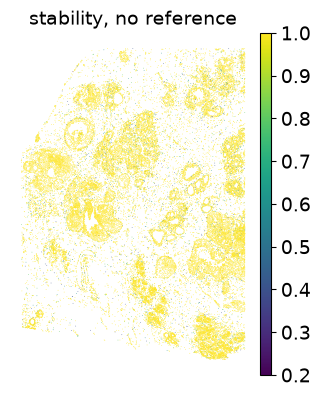

In [17]:
restarts = adata.uns["cn_none"]["restarts"]
print(f"fit kept: {restarts['chosen']}, aneuploid cells per fit: {restarts['n_aneuploid'].tolist()}")
print(pd.DataFrame(restarts["agreement"]).round(3).to_string())
stability = adata.obs["cn_none_stability"]
print(f"cells with a stability below 1: {(stability < 1).mean():.1%}")
print(stability[stability < 1].groupby(adata.obs["group"][stability < 1]).size().loc[lambda s: s > 0].to_string())
cnv.pl.spatial_cnv(adata, color="cn_none_stability", size=1, cmap="viridis", title="stability, no reference")

Of its 5 fits, the run kept fit 4, and the fits make the same call for 95.5% to 98.7% of the cells in each pair.
`copy_number_stability` is the share of the fits whose call matches the cell's label. 6.7% of the cells have a stability
below 1, most of them fibroblasts (1,063 cells) and smooth muscle cells and pericytes (657), and few of them are in the
epithelium of A, C or N. Treat the calls of those cells as uncertain. The restarts make the result depend less on the
seed, but they don't make it more correct, and the stability covers only the call, so a cell with a stability of 1 can
still change its clone between fits.

## Detectability

{func}`infercnvpy.tl.detectability` estimates how many cells of one type, all carrying the same change, a test needs to
detect the gain (1.5x) or loss (0.5x) of a whole arm, from the counts of the cells and the noise of the reference
cells. The table gives the median over the arms, per type.

In [18]:
cnv.tl.detectability(adata, groupby="cell_type_ref", reference_key="cell_type_ref", reference_cat=all_normal)
table = adata.uns["detectability"]["table"]
table.groupby("group", observed=True)[["cells_gain", "cells_loss"]].median().round(1)

,cells_gain,cells_loss
group,,
B/plasma,4.5,3.4
T/NK,6.0,4.6
endothelial,6.3,4.8
epithelial,3.7,2.8
fibroblast,7.8,6.0
myeloid,6.6,5.1
normal epithelium,5.0,3.8
smooth muscle/pericyte,5.6,4.2
unassigned,5.3,4.0


With the whole transcriptome, a test needs about 4 epithelial cells for the median arm to detect a gain and about 3 to
detect a loss. The numbers are for a test that knows the normal expression of each type, and `tl.copy_number` and
`tl.infercnv` need more cells, since they estimate it from the data (see {func}`~infercnvpy.tl.detectability` and the
{doc}`Xenium tutorial <spatial_xenium>`). They also assume that expression follows the DNA copies one to one.

## Summary

- Put every normal cell type that you can annotate into the reference, including stromal cells such as smooth muscle
  cells and pericytes, and normal epithelium.
- Compare the calls per cell type with and without a reference. Many aneuploid calls in a normal type can mean that the
  type is missing from the reference.
- Keep the default of 5 restarts and check `copy_number_stability`. The clones change more between fits than the calls.
- Pseudobulk profiles of regions with known copy number, as here from WGS, are a check of the profiles. The check holds
  at the level of groups of cells, not of single cells.

In [19]:
# versions and threads used to run this notebook; INFERCNVPY_COMMIT is set by the docs build
print("infercnvpy", cnv.__version__, os.environ.get("INFERCNVPY_COMMIT", ""))
for package in ["anndata", "scanpy", "numpy", "pandas", "scipy", "scikit-learn", "numba"]:
    print(package, importlib.metadata.version(package))
print("numba threads", numba.get_num_threads(), "| CPUs", os.cpu_count())

infercnvpy 0.7.0.dev0 bf3dfd4
anndata 0.13.4
scanpy 1.12.6
numpy 2.5.4
pandas 3.1.1
scipy 1.18.1
scikit-learn 1.9.1
numba 0.68.1
numba threads 16 | CPUs 96
